# B 수집 기록 (날씨와 경보)

B가 받은 자료를 **어떤 코드로 → 어떻게 돌렸고 → 무엇이 나왔는지** 한 곳에서 보는 노트북이다.
수집 본체는 `crawling/*.py`(터미널에서 실행)에 있고, 이 노트북은 **핵심 코드 · 실행 로그 · 화면 캡처 · 결과 표**를 읽어서 보여 주기만 한다. 실행해도 아무것도 다시 받거나 덮어쓰지 않는다.

| # | 자료 | 방법 | 코드 |
| --- | --- | --- | --- |
| 1 | 기상특보 (대설 · 호우 · 한파) | **Selenium (B의 동적 크롤링)** | `crawling/kma_warning.py` |
| 2 | ASOS 서울(108) 시간자료 | 공공데이터포털 API | `crawling/kma_asos.py` |
| 3 | 과거 단기예보 · 구별 AWS | 기상청 API허브 | `crawling/kma_apihub.py` |
| 4 | 한강 수위 | 한강홍수통제소 API | `crawling/hrfco_waterlevel.py` |
| 5 | 평소값 · 정체 기준 | C 통행시간 표로 계산 | `src/labels/road_baseline.py` · `src/labels/link_baseline.py` |
| 6 | 실패 · 재시도 모아 보기 | 위 로그 전체 | `logs/ljh/*/*.log` |

**커밋 전**: Kernel → Restart & Run All 후 결과까지 저장해서 커밋한다.

In [1]:
from pathlib import Path
import ast, json, re
import pandas as pd
from IPython.display import Image, Markdown, display

def find_project_root(start=None):
    """지금 폴더에서 위로 올라가며 README.md와 .git이 있는 저장소 루트를 찾는다."""
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "README.md").is_file() and (candidate / ".git").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트를 찾지 못했습니다.")

ROOT = find_project_root()
pd.set_option("display.max_columns", 30)


def show_func(rel, *names):
    """파이썬 파일에서 함수 몇 개만 골라 보여 준다 (import 하지 않아서 Selenium 없이도 된다)."""
    src = (ROOT / rel).read_text(encoding="utf-8")
    lines = src.splitlines()
    for node in ast.parse(src).body:
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
            start = (node.decorator_list[0].lineno if node.decorator_list else node.lineno) - 1
            body = "\n".join(lines[start:node.end_lineno])
            display(Markdown(f"**`{rel}` · `{node.name}()`** ({start + 1}–{node.end_lineno}행)\n```python\n{body}\n```"))


def log_summary(rel, pattern=None, n=8):
    """실행 로그: 기간 · 줄 수 · INFO/WARNING/ERROR 수 + (pattern에 맞는) 마지막 n줄."""
    lines = (ROOT / rel).read_text(encoding="utf-8", errors="replace").splitlines()
    levels = pd.Series([l.split()[2] for l in lines if len(l.split()) > 2 and l[:2] == "20"]).value_counts()
    print(f"{rel} · {len(lines):,}줄 · {lines[0][:16]} ~ {lines[-1][:16]}")
    print("  " + " · ".join(f"{k} {v:,}" for k, v in levels.items() if k in ("INFO", "WARNING", "ERROR")))
    pick = [l for l in lines if re.search(pattern, l)] if pattern else lines
    print("\n".join("  " + l[:160] for l in pick[-n:]))


def show_table(rel, n=3):
    """결과 표: 행 · 열 수와 앞 n줄."""
    p = ROOT / rel
    d = pd.read_parquet(p) if p.suffix == ".parquet" else pd.read_csv(p)
    print(f"{rel} · {len(d):,}행 × {d.shape[1]}열")
    display(d.head(n))
    return d


def read_split(name):
    """data/shared/{train_dev,holdout}/{name}_{split}.csv 를 합쳐서 읽는다."""
    return pd.concat([pd.read_csv(ROOT / f"data/shared/{s}/{name}_{s}.csv") for s in ("train_dev", "holdout")],
                     ignore_index=True)

---
## 1. 기상특보 · Selenium (B의 동적 크롤링)

- **출처**: [기상자료개방포털 · 기상특보](https://data.kma.go.kr/data/weatherReport/wsrList.do?pgmNo=647)
- **흐름**: 기간 입력 → 지역 · 특보 종류 트리 펼치고 체크 → 조회 → **결과 표가 새로 그려질 때까지 대기** → 페이지 넘김 → 통보문 상세
- **실행**: `python crawling/kma_warning.py --start 2022-10-01 --end 2026-09-30` (11/20)
- **어려웠던 점**: JS와 Selenium 표시 검사 충돌(`computedStyleCache.set is not a function`) → 존재 대기 + `get_dom_attribute`로 해결. 한파 "서울(서울동남권 제외)"를 거꾸로 읽음 → '제외' 처리 추가

### 1-1. 핵심 코드 (조건 설정 → 조회 → 페이지 넘김 → 행 읽기)

이 페이지는 조회 버튼을 누르면 **화면 일부가 JS로 다시 그려지는** 동적 페이지라, "클릭했다"가 아니라 "**새 결과가 화면에 나왔다**"를 확인한 뒤에 읽는 것이 핵심이다.

| 함수 | 하는 일 | 동적 페이지라서 한 처리 |
| --- | --- | --- |
| `set_conditions()` | 기간 입력 → 지역 · 특보 종류 트리 펼치고 체크 → 한 쪽 100건 | 날짜칸이 달력 위젯이라 `execute_script`로 값을 직접 넣음. 트리는 펼침 버튼을 눌러야 항목이 생겨서 `check_tree()`에서 기다린 뒤 체크 |
| `click_search()` | 조회 버튼 클릭 | 클릭 전 폼(`old`)을 기억해 두고 `staleness_of(old)`로 **옛 화면이 사라질 때까지**, 이어서 상세 버튼(`a.btn_more`)이 **생길 때까지** 기다림 → 이전 결과를 읽는 실수 방지 |
| `go_page()` | n쪽으로 이동 | 1–10쪽은 링크 클릭, 11쪽부터는 페이지 묶음이 바뀌어 화면의 `changePage(n)` JS를 직접 호출. 첫 행이 사라지고 `pageIndex`가 n이 될 때까지 대기 |
| `read_rows()` | 표의 행 → 발표 시각 · 지역 · 제목 · 상세 키 | 상세 키는 버튼의 `onclick` 속성에 들어 있어 정규식으로 꺼냄. `get_dom_attribute`로 DOM에서 직접 읽어 사이트 JS와의 충돌(`computedStyleCache` 오류)을 피함 |

In [2]:
show_func("crawling/kma_warning.py", "set_conditions", "click_search", "go_page", "read_rows")

**`crawling/kma_warning.py` · `set_conditions()`** (89–100행)
```python
def set_conditions(driver, wait, start, end):
    driver.get(URL)
    wait.until(EC.presence_of_element_located((By.ID, "schForm")))
    shot(driver, "1_before")
    # 날짜: 달력 입력칸이라 값을 직접 넣는다
    for fid, val in (("startDt", start), ("endDt", end)):
        el = driver.find_element(By.ID, fid)
        driver.execute_script("arguments[0].value = arguments[1];", el, val.replace("-", ""))
    check_tree(driver, wait, "ztree1", "ztree1_2_switch", [REGION])
    check_tree(driver, wait, "ztree", "ztree_2_switch", KINDS)
    Select(driver.find_element(By.ID, "selectSchListCnt")).select_by_value(PAGE_SIZE)
    shot(driver, "2_conditions")
```

**`crawling/kma_warning.py` · `click_search()`** (103–108행)
```python
def click_search(driver, wait):
    old = driver.find_element(By.ID, "schForm")
    driver.find_element(By.XPATH, "//button[contains(@onclick,'searchData')]").click()
    wait.until(EC.staleness_of(old))  # 폼 제출로 화면이 새로 그려질 때까지
    wait.until(EC.presence_of_element_located((By.CSS_SELECTOR, "table tbody tr a.btn_more")))
    shot(driver, "3_result")
```

**`crawling/kma_warning.py` · `read_rows()`** (111–123행)
```python
def read_rows(driver):
    rows = []
    for tr in driver.find_elements(By.CSS_SELECTOR, "table tbody tr"):
        links = tr.find_elements(By.CSS_SELECTOR, "a.btn_more")
        if not links:
            continue
        tds = tr.find_elements(By.TAG_NAME, "td")
        m = ONCLICK_RE.search(links[0].get_dom_attribute("onclick"))
        rows.append({
            "issued_at": tds[0].text.strip(), "region": tds[1].text.strip(), "title": tds[2].text.strip(),
            "fcTma": m.group(1), "no": m.group(2), "inpTma": m.group(3), "stn": m.group(4),
        })
    return rows
```

**`crawling/kma_warning.py` · `go_page()`** (126–135행)
```python
def go_page(driver, wait, n):
    first = driver.find_element(By.CSS_SELECTOR, "table tbody tr")
    links = [a for a in driver.find_elements(By.CSS_SELECTOR, f"a[onclick^='changePage({n});']")
             if a.text.replace("\n", "").strip() == f"{n}페이지"]
    if links:
        links[0].click()
    else:  # 11쪽부터는 페이지 묶음이 바뀌므로 화면의 changePage 함수를 직접 부른다
        driver.execute_script(f"changePage({n});")
    wait.until(EC.staleness_of(first))
    wait.until(lambda d: d.find_element(By.ID, "pageIndex").get_property("value") == str(n))
```

### 1-2. 실행 화면 (전 → 조건 → 결과 → 상세)

**kma_warning_1_before**

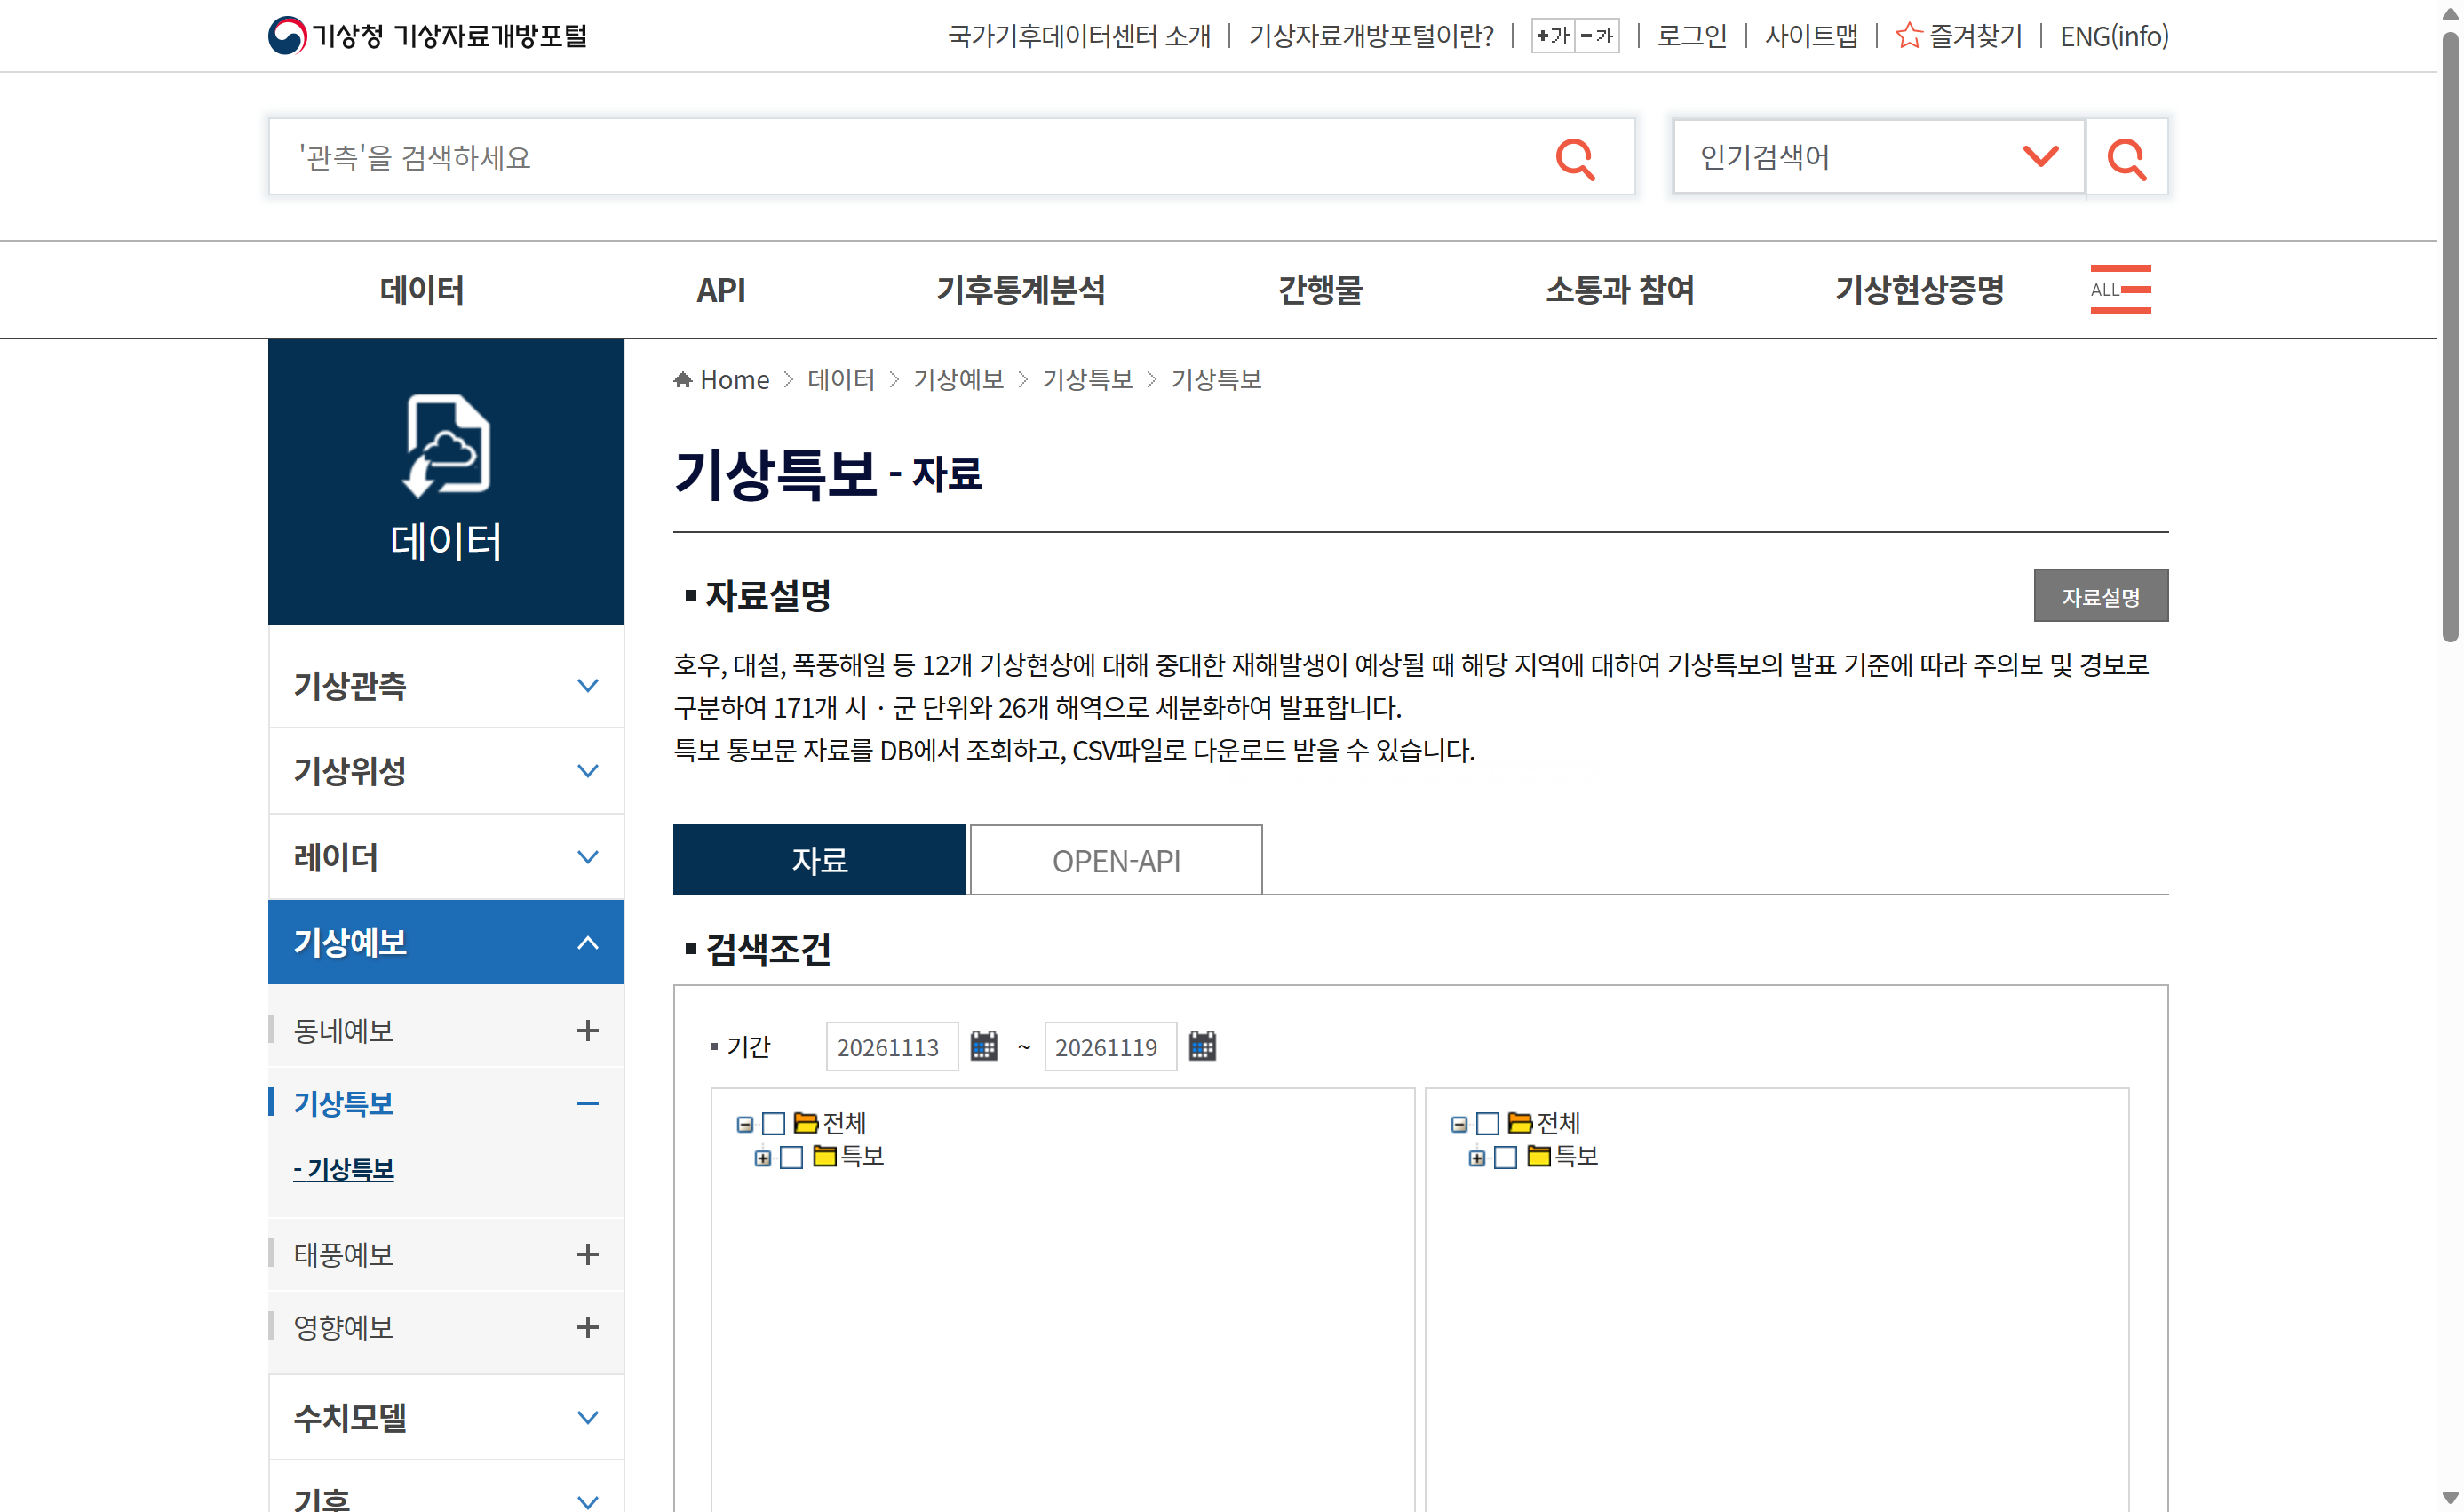

**kma_warning_2_conditions**

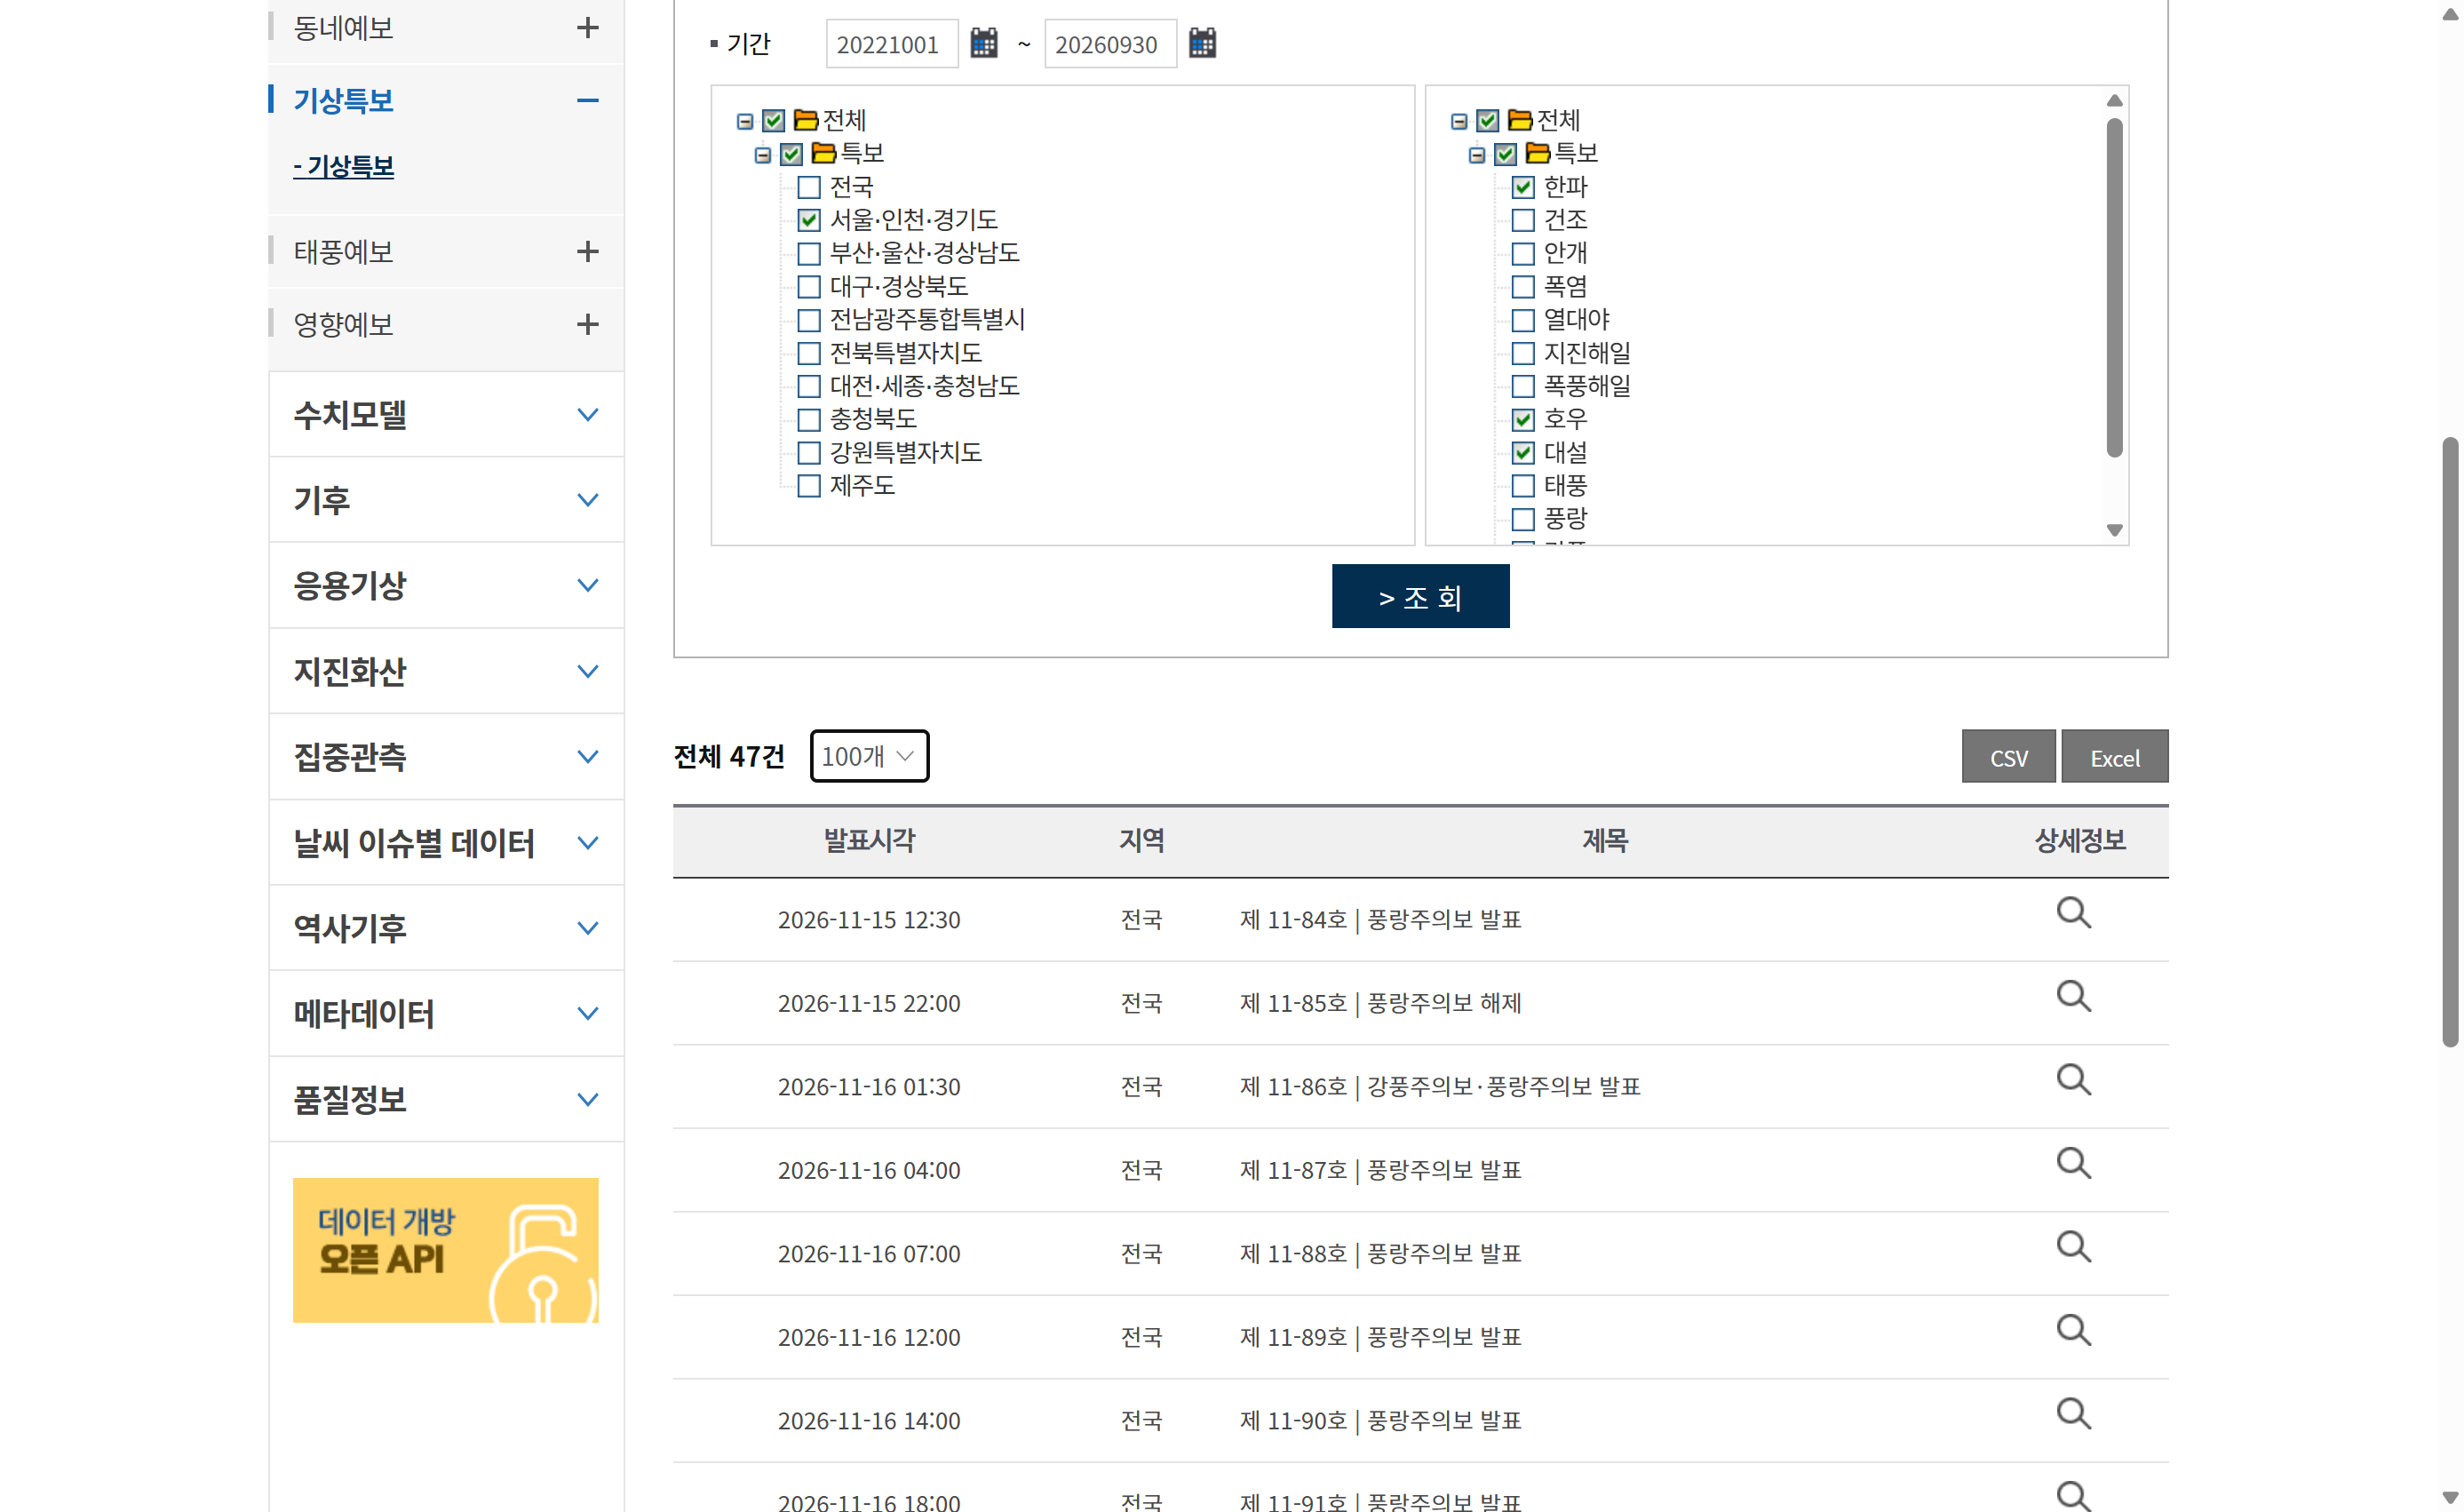

**kma_warning_3_result**

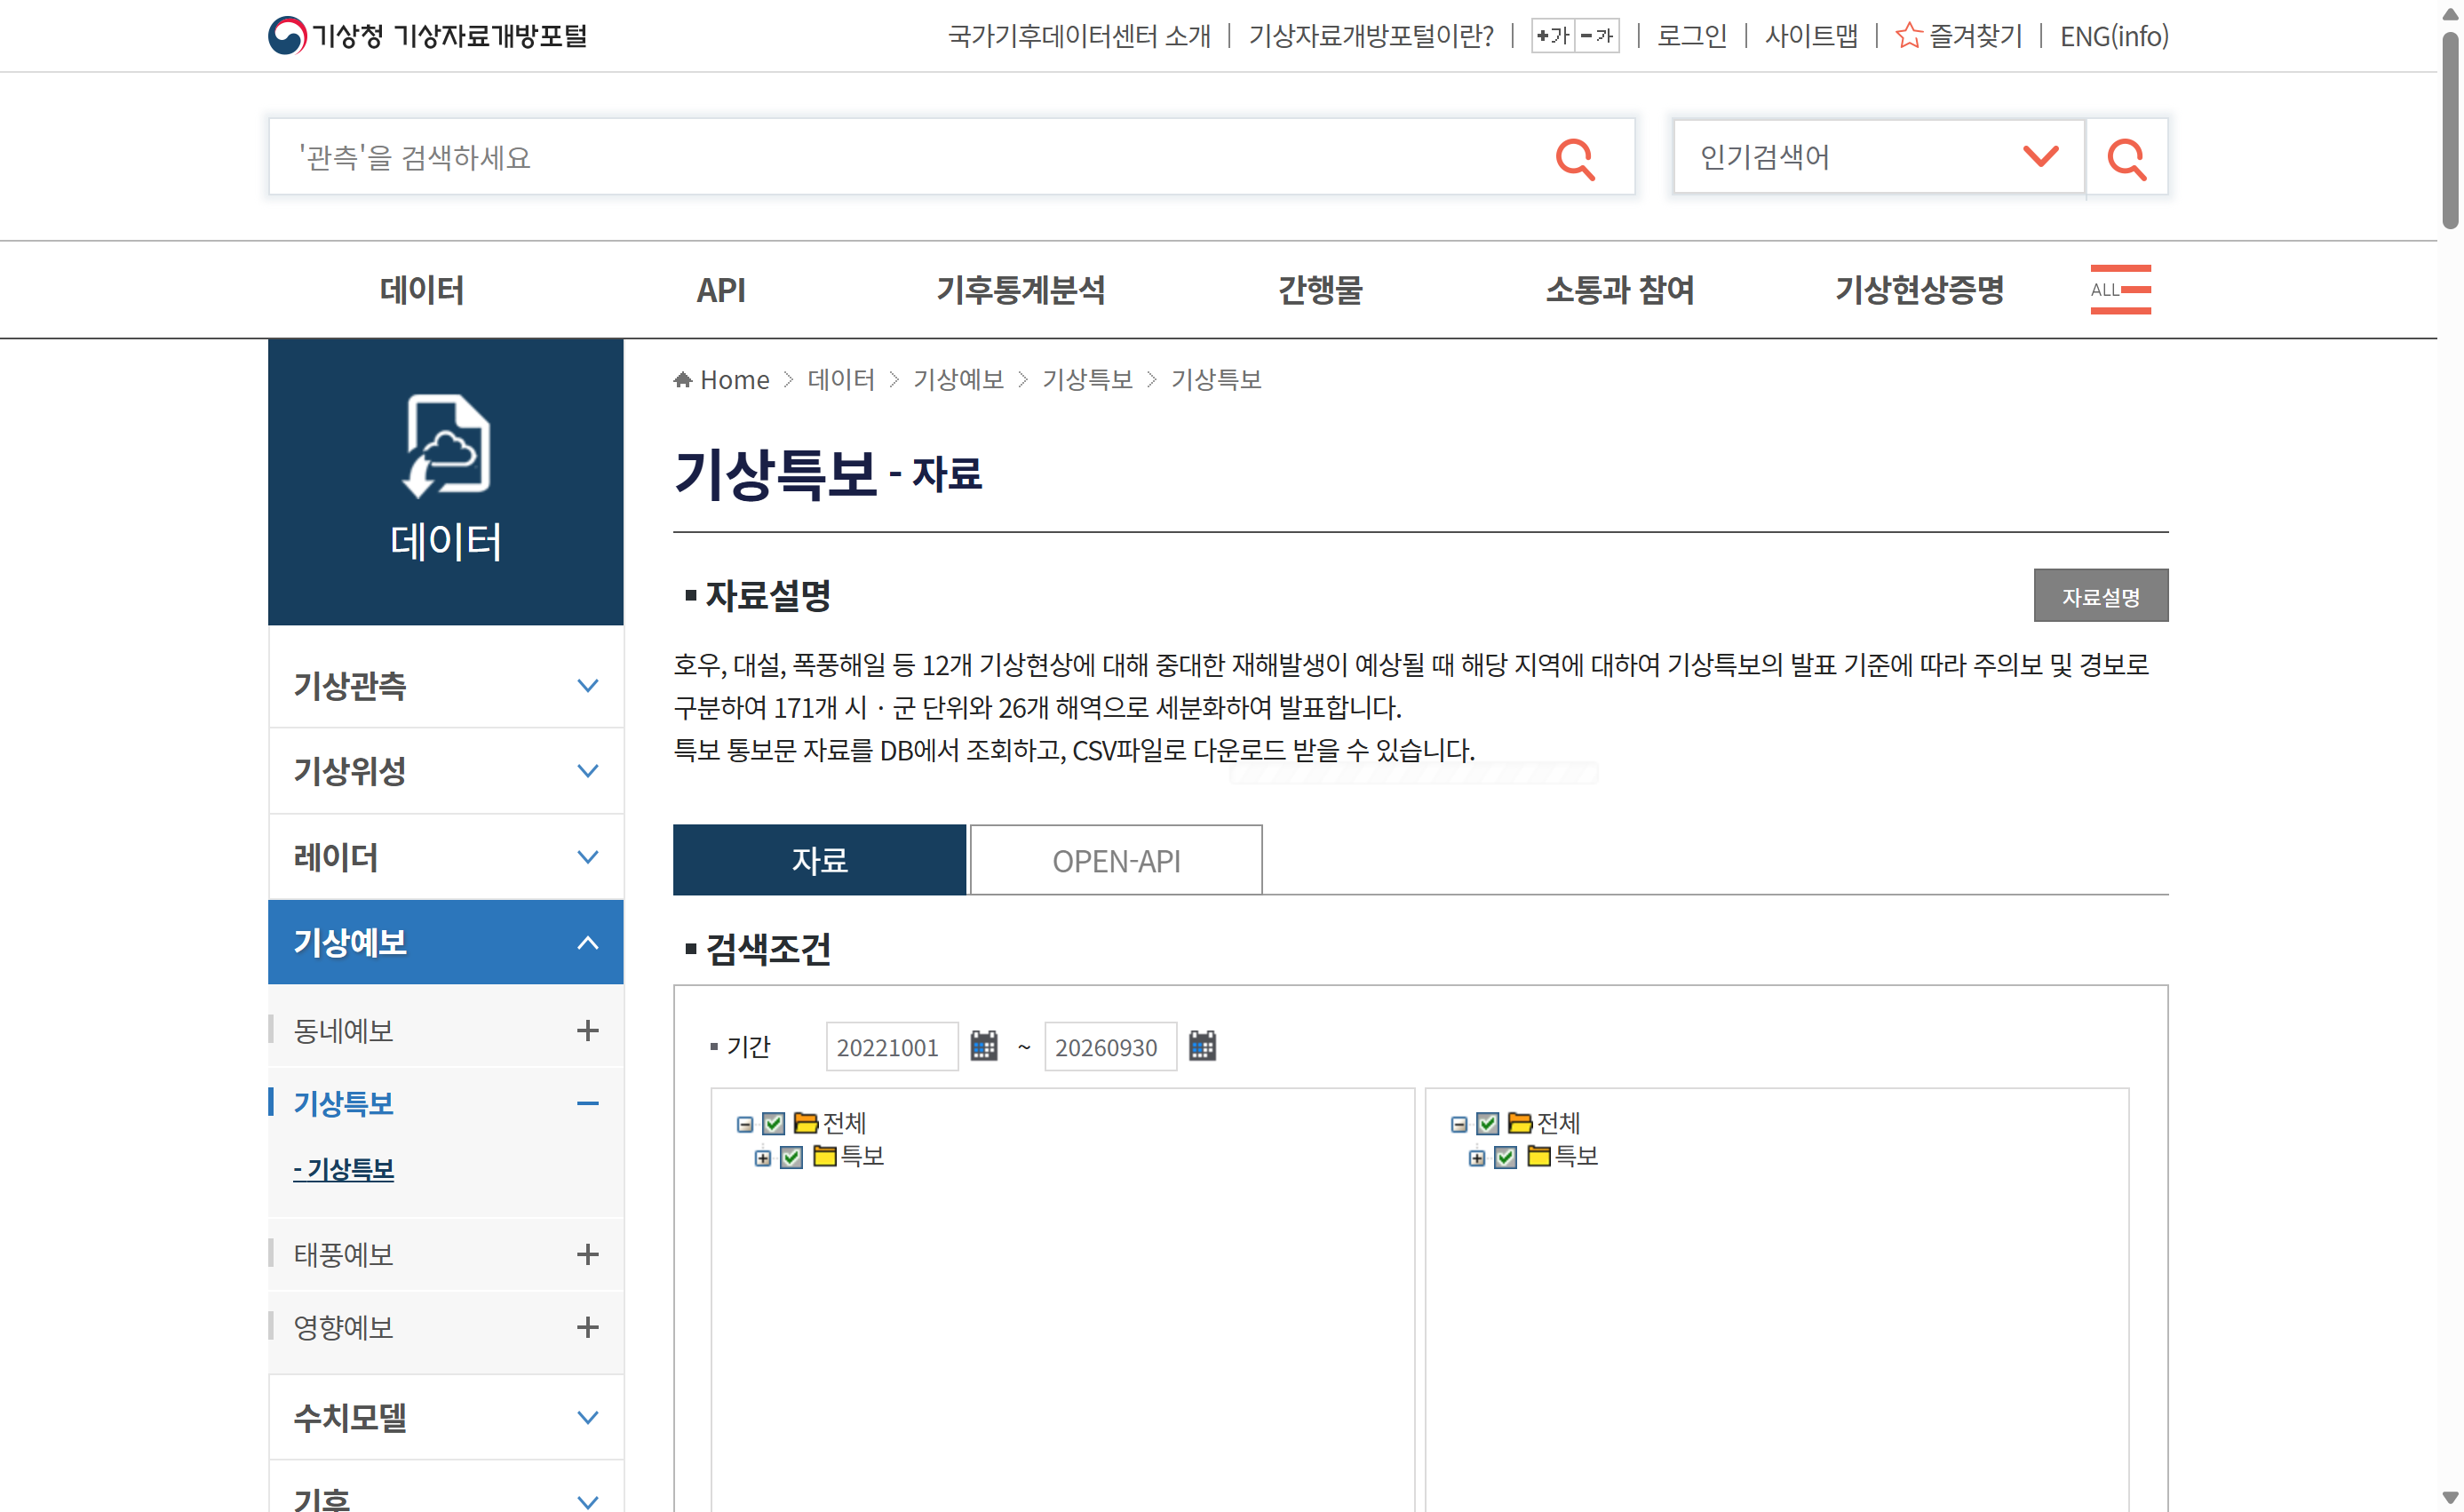

**kma_warning_4_detail_popup**

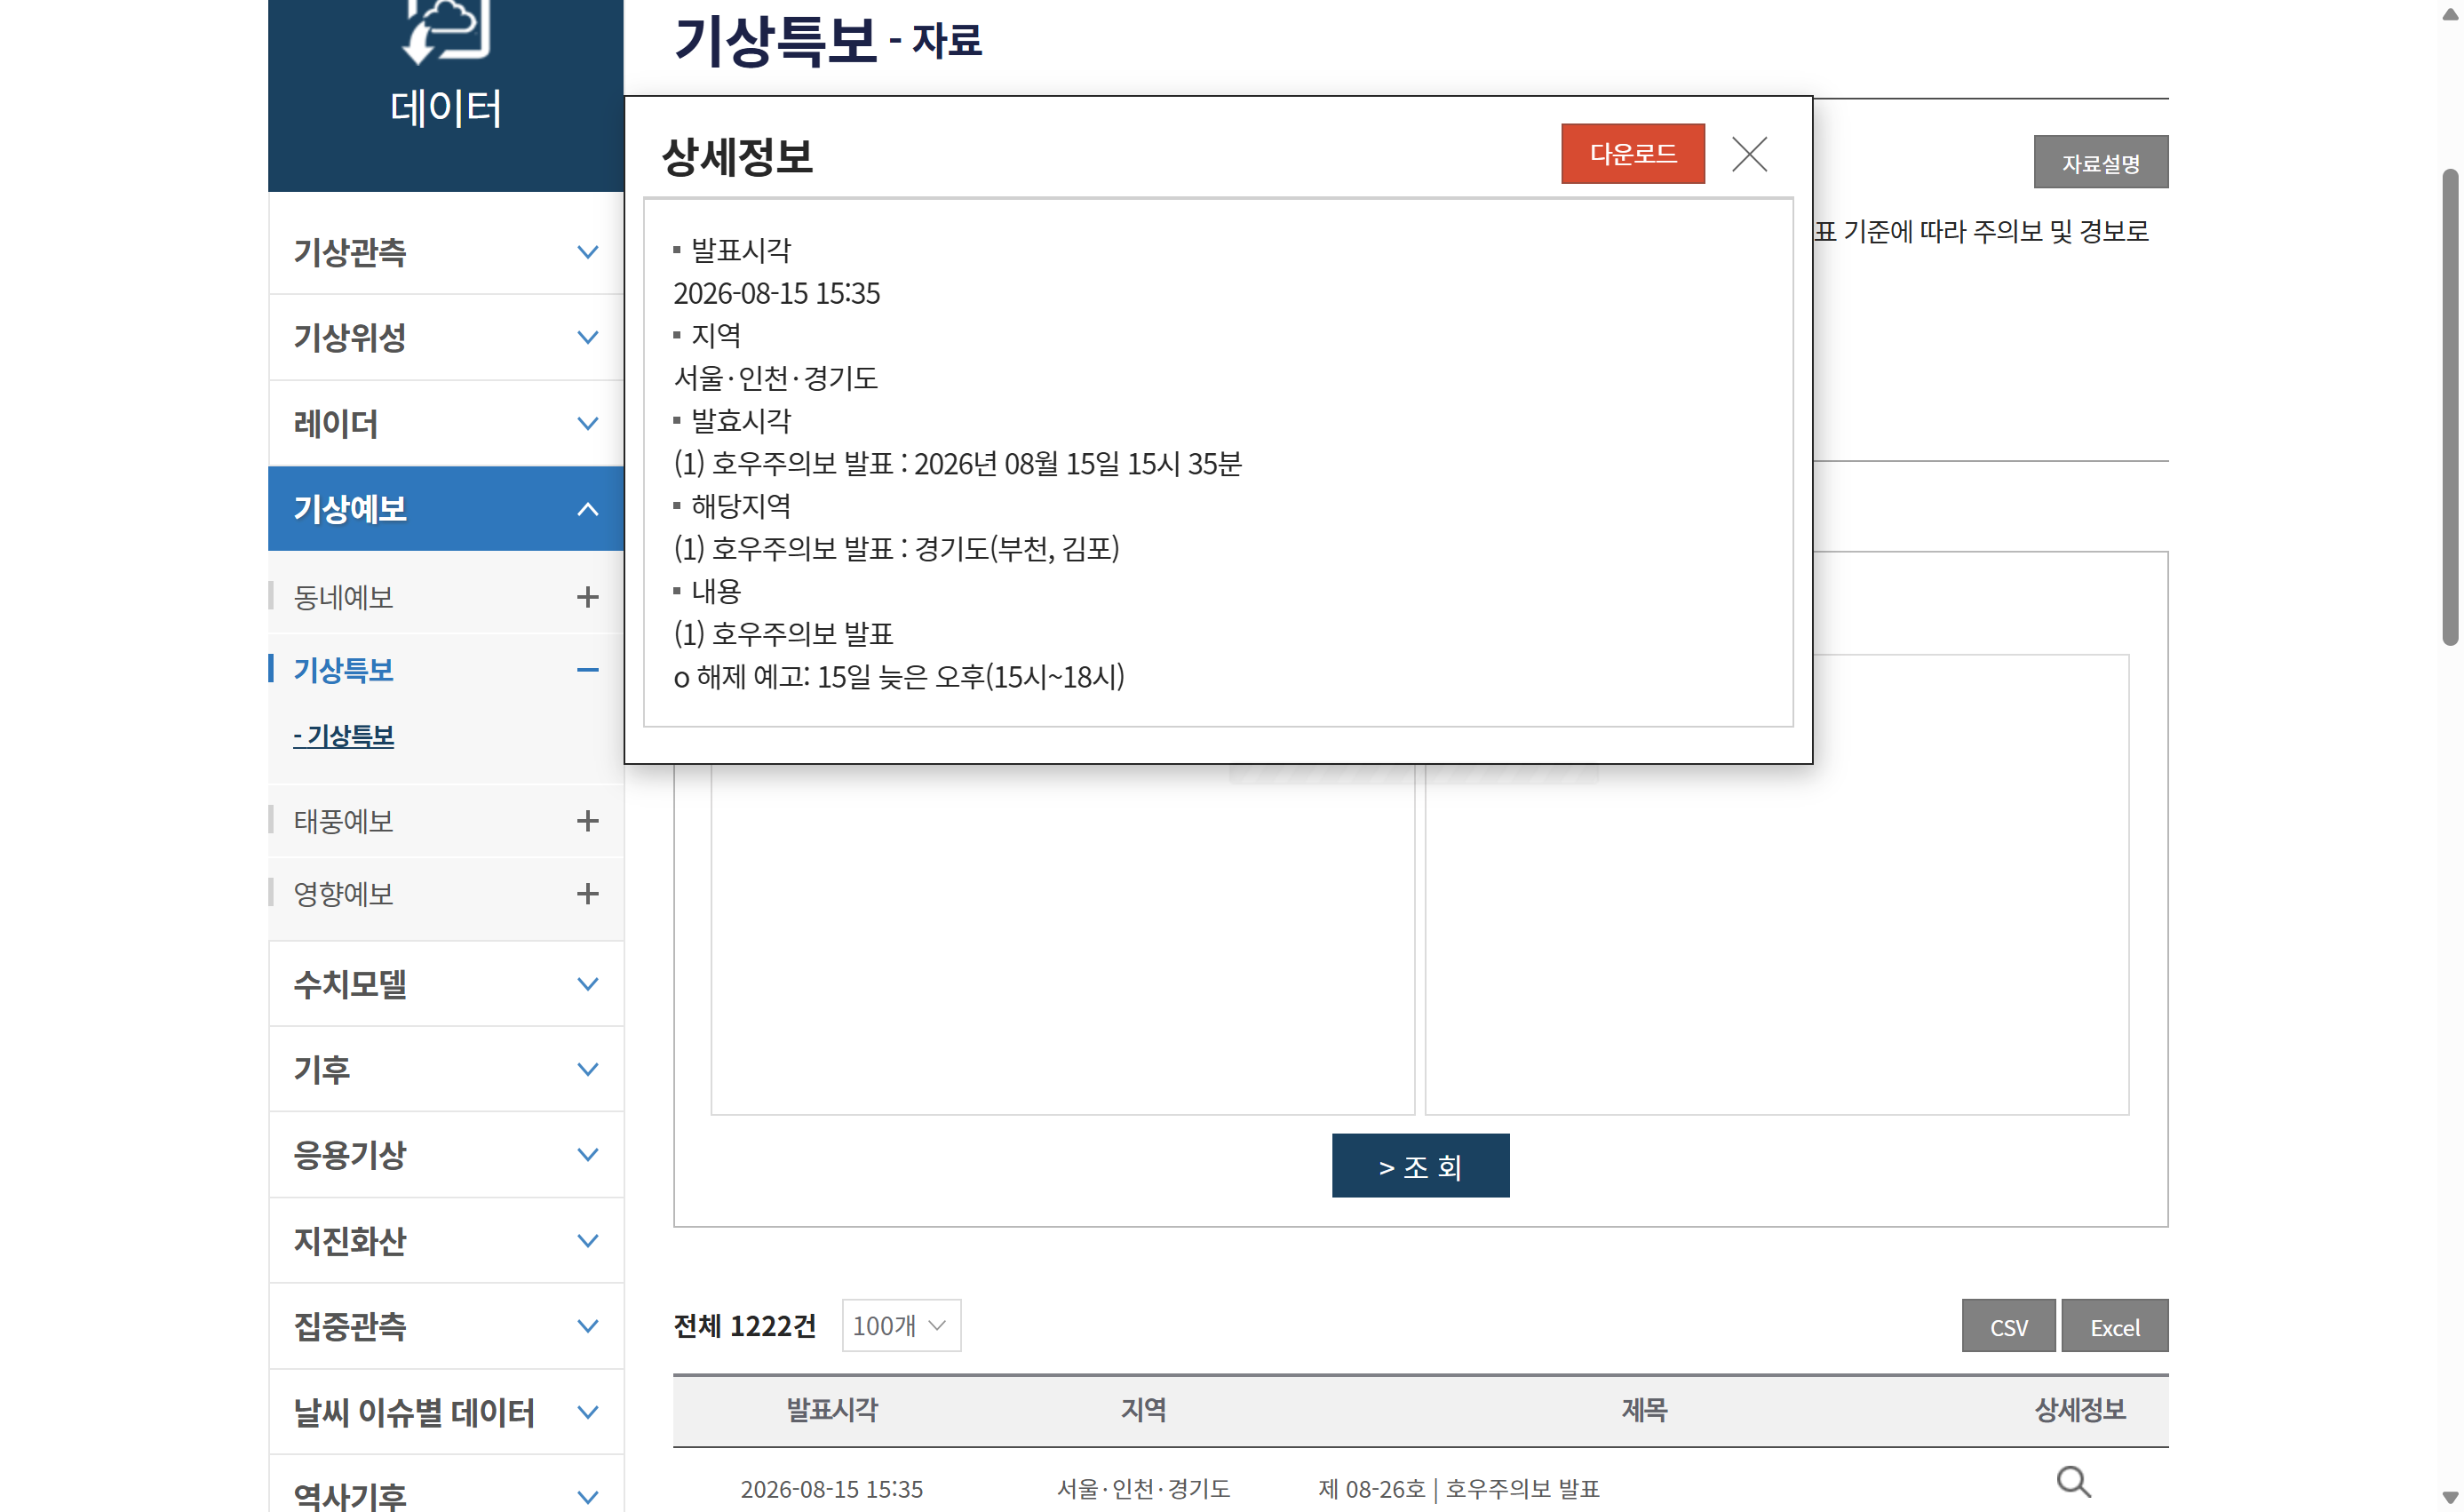

In [3]:
for p in sorted((ROOT / "logs/ljh/kma_warning").glob("kma_warning_*.png")):
    display(Markdown(f"**{p.stem}**"), Image(filename=str(p), width=750))

### 1-3. 실행 로그

In [4]:
log_summary("logs/ljh/kma_warning/kma_warning.log", pattern="검색 결과|쪽 · 누적|저장|끝|WARNING|ERROR")

logs/kma_warning.log · 60줄 · 2026-11-20 22:08 ~ 2026-11-20 22:26
  INFO 35 · WARNING 1
  2026-11-20 22:18:01,685 INFO 9/13쪽 · 누적 900건
  2026-11-20 22:18:11,682 INFO 10/13쪽 · 누적 1000건
  2026-11-20 22:18:21,887 INFO 11/13쪽 · 누적 1100건
  2026-11-20 22:18:31,592 INFO 12/13쪽 · 누적 1200건
  2026-11-20 22:18:34,753 INFO 13/13쪽 · 누적 1222건
  2026-11-20 22:18:34,799 INFO 목록 저장 1222건
  2026-11-20 22:18:36,884 WARNING 상세 팝업 캡처 실패: Message: javascript error: Cannot read properties of undefined (reading 'stopPropagation')
  2026-11-20 22:26:28,957 INFO 상세 저장 1222건 · 끝


### 1-4. 결과: 전체 통보문 → 서울 해당 → 서울 특보 구간

In [5]:
lst = show_table("data/raw/kma_warning/warning_list.csv")
items = show_table("outputs/tables/seoul_warning_items.csv")
warn = read_split("weather_warnings")
print(f"서울 특보 구간 {len(warn)}개")
warn.groupby(["split", "kind"]).agg(구간=("hours", "size"), 총시간=("hours", "sum")).unstack(0)

data/raw/kma_warning/warning_list.csv · 1,222행 × 7열


,issued_at,region,title,fcTma,no,inpTma,stn
0,2022-10-03 18:20,서울·인천·경기도,제 10-4호 | 호우주의보 발표,2022-10-03 18:20,4,20221003182501,109
1,2022-10-03 20:10,서울·인천·경기도,제 10-5호 | 호우주의보 발표,2022-10-03 20:10,5,20221003201400,109
2,2022-10-03 21:00,서울·인천·경기도,제 10-7호 | 호우경보 변경·호우주의보 발표,2022-10-03 21:00,7,20221003210113,109


outputs/tables/seoul_warning_items.csv · 257행 × 12열


,item,kind_ko,level_ko,action,effective_at,areas,issued_at,title,inpTma,kind,level,seoul_areas
0,1,호우,주의보,발표,2022-10-03 22:00:00,"경기도(고양), 서울(동북권, 서북권)",2022-10-03 22:00:00,제 10-9호 | 호우주의보 발표,20221003220653,rain,1,"동북권,서북권"
1,1,호우,주의보,해제,2022-10-04 01:30:00,"경기도(가평, 고양, 양주, 의정부, 구리, 남양주, 하남), 서울(동북권, 서북권)",2022-10-04 01:30:00,제 10-14호 | 호우주의보 해제,20221004013251,rain,1,"동북권,서북권"
2,2,한파,경보,발표,2022-11-29 18:00:00,"경기도, 서울, 인천(옹진군 제외)",2022-11-29 10:00:00,제 11-20호 | 풍랑경보 변경·한파경보·한파주의보 발표,20221129100232,cold,2,"동남권,동북권,서남권,서북권"


서울 특보 구간 89개


구간        총시간      
split eval train eval train
kind                       
cold     9    15  454   699
rain     6    39   22   268
snow     3    17    8   141

---
## 2. ASOS 서울(108) 시간자료 · 공공데이터포털 API

- **실행**: `python crawling/kma_asos.py` (2022-10 ~ 2026-09, 이미 받은 달은 건너뜀)
- **어려웠던 점**: 키가 맞는데 403 → 서비스마다 활용신청이 따로 필요. 로그에 키가 찍힘 → `***`로 가리도록 수정

In [6]:
show_func("crawling/kma_asos.py", "fetch_month")

**`crawling/kma_asos.py` · `fetch_month()`** (64–95행)
```python
def fetch_month(key, year, month, retries=3):
    last_day = calendar.monthrange(year, month)[1]
    params = {
        "serviceKey": key,
        "pageNo": 1,
        "numOfRows": 999,  # 한 달은 최대 744시간이라 한 페이지로 받는다
        "dataType": "JSON",
        "dataCd": "ASOS",
        "dateCd": "HR",
        "startDt": f"{year}{month:02d}01",
        "startHh": "00",
        "endDt": f"{year}{month:02d}{last_day:02d}",
        "endHh": "23",
        "stnIds": STATION,
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(URL, params=params, timeout=30)
            r.raise_for_status()
            body = r.json()["response"]
            code = body["header"]["resultCode"]
            if code != "00":
                raise RuntimeError(f"API 오류 {code}: {body['header'].get('resultMsg')}")
            items = body["body"]["items"]["item"]
            return pd.DataFrame(items), last_day * 24
        except Exception as e:  # noqa: BLE001
            msg = str(e).replace(key, "***")  # 로그에 인증키가 남지 않게 가린다
            if "403" in msg:
                msg += " → 이 API의 활용신청이 안 됐거나 아직 승인 전일 수 있음"
            logging.warning("%d-%02d 시도 %d/%d 실패: %s", year, month, attempt, retries, msg)
            time.sleep(2 * attempt)
    raise RuntimeError(f"{year}-{month:02d} 수집 실패")
```

In [7]:
log_summary("logs/ljh/kma_asos/kma_asos.log", pattern="완료|저장|WARNING|ERROR", n=5)
raw = sorted((ROOT / "data/raw/asos").glob("asos_108_*.csv"))
print(f"\n원본 {len(raw)}개월: {raw[0].stem[-6:]} ~ {raw[-1].stem[-6:]}")

logs/kma_asos.log · 54줄 · 2026-11-20 21:29 ~ 2026-11-20 21:43
  INFO 51 · WARNING 3
  2026-11-20 21:43:11,301 INFO asos_108_202605.csv: 744행 저장
  2026-11-20 21:43:15,772 INFO asos_108_202606.csv: 720행 저장
  2026-11-20 21:43:19,885 INFO asos_108_202607.csv: 744행 저장
  2026-11-20 21:43:24,191 INFO asos_108_202608.csv: 744행 저장
  2026-11-20 21:43:28,179 INFO asos_108_202609.csv: 720행 저장

원본 48개월: 202210 ~ 202609


### 2-1. 결과: 시간별 날씨 표 · 악천후 사건 · 악천후일/비교일

In [8]:
hourly = read_split("weather_hourly")
events = read_split("weather_events")
days = read_split("weather_days")
print(f"시간 표 {len(hourly):,}행 · 사건 {len(events)}개 · 악천후일/비교일 {len(days)}일")
display(hourly[hourly["in_period"]].groupby(["split", "impact"], dropna=False).size().unstack(0))
days.groupby(["split", "role"]).size().unstack(0)

시간 표 35,064행 · 사건 539개 · 악천후일/비교일 90일


split,eval,train
impact,,
강한 비,276,1023
많은 눈,39,272
보통 눈,103,517
호우,42,415
NaN,5348,15221


split,eval,train
role,,
비교일,15,30
악천후일,15,30


---
## 3. 과거 단기예보 · 구별 AWS · 기상청 API허브

- **대상**: 연구 기간 평일 전체 654일 (11/26에 악천후일 · 비교일 90일에서 넓힘. 90일에만 값이 있으면 모델이 '값이 있으면 악천후일'을 배우기 때문). 예보는 서울 4개 권역 격자에서 출퇴근 시각을 1 · 3시간 전에 볼 수 있던 발표만, AWS는 29개 지점 · 하루 36시간
- **실행**: `python crawling/kma_apihub.py --part full --workers 4` (하루 한도에서 멈추면 다음 날 같은 명령으로 이어 받기) → `--parse`
- **어려웠던 점**: 과거 예보 API(getVilageFcst)는 최근 3일만 줌 → 격자 API로 변경, 격자 순서는 `--probe`로 관측과 대조해 남쪽부터로 확정. 504 지연 → 동시 4개 · 실패 건 건너뛰고 이어받기
- **주의**: `fcst` 표의 `lead_h`는 발표 → 예보 시각 간격(2–6시간)이다. 1 · 3시간 전 구분이 아니다.

In [9]:
show_func("crawling/kma_apihub.py", "get", "run_jobs")

**`crawling/kma_apihub.py` · `get()`** (180–200행)
```python
def get(session, url, params, key, calls, today):
    """요청 1번 (재시도 포함). 인증키는 오류 메시지에서 가린다."""
    params = dict(params, authKey=key)
    last = None
    for attempt in range(1, RETRIES + 1):
        add_call(calls, today)
        try:
            r = session.get(url, params=params, timeout=(10, 60))
            text = r.text
            if r.status_code in (401, 403) or "인증" in text[:300] or "not authorized" in text[:300].lower():
                raise AuthError(f"HTTP {r.status_code}: {text[:200]}")
            r.raise_for_status()
            time.sleep(PAUSE_SEC)
            return text
        except AuthError:
            raise
        except requests.RequestException as e:
            last = str(e).replace(key, "***")
            log.warning("  재시도 %d/%d: %s", attempt, RETRIES, last[:200])
            time.sleep(3 * attempt)
    raise RuntimeError(f"{RETRIES}번 시도 후 실패: {last}")
```

**`crawling/kma_apihub.py` · `run_jobs()`** (323–353행)
```python
def run_jobs(label, jobs, fetch, workers, t0):
    """jobs를 workers개 스레드로 받는다. 3번 실패한 건은 건너뛰고 끝에 개수를 알린다
    (다시 실행하면 그것만 이어 받는다). 인증 오류 · 하루 한도면 전부 멈춘다."""
    local = threading.local()

    def one(job):
        if not hasattr(local, "session"):
            local.session = requests.Session()
        return fetch(local.session, job)

    failed = 0
    with ThreadPoolExecutor(max_workers=max(1, workers)) as ex:
        futures = [ex.submit(one, job) for job in jobs]
        try:
            for i, fut in enumerate(as_completed(futures), 1):
                try:
                    fut.result()
                except (AuthError, LimitReached):
                    raise
                except Exception as e:  # 3번 재시도 후 실패, 응답 형식 오류 등
                    failed += 1
                    log.warning("  [%s] 건너뜀 (%d건째): %s", label, failed, str(e)[:200])
                if i % 100 == 0 or i == len(jobs):
                    log.info("  %s %d/%d (실패 %d · %.0f초)", label, i, len(jobs), failed, time.time() - t0)
        except (AuthError, LimitReached):
            for f in futures:
                f.cancel()
            raise
    if failed:
        log.warning("  %s %d건 실패 → 같은 명령을 다시 실행하면 실패한 것만 이어 받습니다.", label, failed)
    return failed
```

In [10]:
log_summary("logs/ljh/kma_apihub/kma_apihub.log", pattern="=== part|완료|저장|ERROR", n=10)

logs/kma_apihub.log · 191줄 · 2026-11-21 00:32 ~ 2026-11-22 23:46
  WARNING 101 · INFO 90
  2026-11-22 23:01:56,752 INFO === part all: 90일 · AWS 2844시각(남은 1739) · 예보 720쌍 × 4변수(남은 2412) ===
  2026-11-22 23:44:42,192 INFO 저장: data\shared\train\aws_hourly_train.csv (53617행, 지점 29개)
  2026-11-22 23:44:42,254 INFO 저장: data\shared\train\fcst_train.csv (1920행)
  2026-11-22 23:44:42,834 INFO 저장: data\shared\eval\aws_hourly_eval.csv (28488행, 지점 29개)
  2026-11-22 23:44:42,916 INFO 저장: data\shared\eval\fcst_eval.csv (960행)
  2026-11-22 23:46:00,384 INFO === part all: 90일 · AWS 2844시각(남은 1) · 예보 720쌍 × 4변수(남은 2) ===
  2026-11-22 23:46:06,930 INFO 저장: data\shared\train\aws_hourly_train.csv (53646행, 지점 29개)
  2026-11-22 23:46:06,961 INFO 저장: data\shared\train\fcst_train.csv (1920행)
  2026-11-22 23:46:07,206 INFO 저장: data\shared\eval\aws_hourly_eval.csv (28488행, 지점 29개)
  2026-11-22 23:46:07,230 INFO 저장: data\shared\eval\fcst_eval.csv (960행)


In [11]:
fcst = read_split("fcst")
aws = read_split("aws_hourly")
print(f"예보 {len(fcst):,}건 · 권역 {fcst['region'].nunique()}개 · lead_h {sorted(map(int, fcst['lead_h'].unique()))}")
print(f"AWS {aws['datetime'].nunique():,}시각 · 지점 {aws['STN'].nunique()}개")
fcst.head()

예보 2,880건 · 권역 4개 · lead_h [2, 3, 4, 5, 6]
AWS 2,844시각 · 지점 29개


,base,fcst,lead_h,region,PCP,PTY,SNO,TMP
0,2022-12-21 02:00:00,2022-12-21 08:00:00,6,동남권,0.0,3.0,0.0,2.0
1,2022-12-21 02:00:00,2022-12-21 08:00:00,6,동북권,0.0,3.0,2.0,0.0
2,2022-12-21 02:00:00,2022-12-21 08:00:00,6,서남권,0.0,3.0,0.0,2.0
3,2022-12-21 02:00:00,2022-12-21 08:00:00,6,서북권,0.0,3.0,4.0,0.0
4,2022-12-21 05:00:00,2022-12-21 08:00:00,3,동남권,2.0,3.0,2.0,2.0


---
## 4. 한강 수위 · 한강홍수통제소 API

- **대상**: 서울 수위 관측소 19곳 × 2023–2026년 5–9월(20개월) = 380건, 10분 수위 → 끝 시각 기준 시간 표
- **실행**: `python crawling/hrfco_waterlevel.py` → `--parse`

In [12]:
show_func("crawling/hrfco_waterlevel.py", "get_json", "collect")

**`crawling/hrfco_waterlevel.py` · `get_json()`** (101–130행)
```python
def get_json(key, path, tries=4):
    """BASE/{key}/{path} 를 받아 JSON 으로. 실패하면 http · https 를 번갈아 다시 시도."""
    last = ""
    for i in range(tries):
        url = f"{BASES[i % len(BASES)]}/{key}/{path}"
        try:
            r = session().get(url, timeout=60)
            text = r.text
            if r.status_code in (401, 403):
                raise AuthError(f"HTTP {r.status_code}: {text[:200]}")
            r.raise_for_status()
            try:
                data = r.json()
            except ValueError:
                low = text.lower()
                if "key" in low or "인증" in text:
                    raise AuthError(text[:200])
                raise ValueError(f"JSON 아님: {text[:200]}")
            if "content" not in data:
                msg = json.dumps(data, ensure_ascii=False)[:300]
                if "key" in msg.lower() or "인증" in msg:
                    raise AuthError(msg)
                raise ValueError(f"content 없음: {msg}")
            return data
        except AuthError:
            raise
        except Exception as e:  # noqa: BLE001
            last = str(e).replace(key, "***")
            time.sleep(2 * (i + 1))
    raise RuntimeError(last)
```

**`crawling/hrfco_waterlevel.py` · `collect()`** (222–251행)
```python
def collect(key, codes, workers=1, dry_run=False):
    jobs = [(c, y, m) for c in codes for y in YEARS for m in MONTHS if not raw_path(c, y, m).exists()]
    total = len(codes) * len(YEARS) * len(MONTHS)
    log.info("관측소 %d곳 × %d개월 = %d건 중 남은 것 %d건", len(codes), len(YEARS) * len(MONTHS), total, len(jobs))
    if dry_run or not jobs:
        return
    t0, done, fails = time.time(), 0, []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = {ex.submit(fetch_month, key, *j): j for j in jobs}
        for f in as_completed(futs):
            c, y, m = futs[f]
            try:
                n = f.result()
                done += 1
                if n == 0:
                    log.warning("%s %d-%02d: 자료 0건 (관측 안 한 달일 수 있음)", c, y, m)
                if done % 20 == 0 or done == len(jobs):
                    log.info("  %d/%d 완료 (%.0f초)", done, len(jobs), time.time() - t0)
            except AuthError as e:
                log.error("인증 오류로 멈춥니다: %s", str(e).replace(key, "***"))
                log.error("→ api_keys.txt 의 HRFCO_KEY 를 확인하세요.")
                for x in futs:
                    x.cancel()
                raise SystemExit(1)
            except Exception as e:  # noqa: BLE001
                fails.append((c, y, m))
                log.warning("%s %d-%02d 실패 (건너뜀): %s", c, y, m, str(e).replace(key, "***")[:200])
            time.sleep(0.2)
    log.info("끝: 성공 %d건 · 실패 %d건 (%.0f초). 실패한 건은 다시 실행하면 받는다.",
             done, len(fails), time.time() - t0)
```

In [13]:
log_summary("logs/ljh/hrfco_waterlevel/hrfco_waterlevel.log", pattern="관측소 \\d+곳|완료|ERROR", n=5)
got = list((ROOT / "data/raw/hanriver_level").glob("wl_*.json"))
print(f"\n받은 원본 {len(got)}/380건")
show_table("data/shared/waterlevel_stations.csv", n=19);

logs/hrfco_waterlevel.log · 52줄 · 2026-11-23 01:29 ~ 2026-11-23 03:44
  INFO 43 · WARNING 6 · ERROR 3
  2026-11-23 02:52:49,938 INFO   340/380 완료 (4271초)
  2026-11-23 03:40:03,490 INFO   360/380 완료 (7105초)
  2026-11-23 03:44:28,357 INFO   380/380 완료 (7370초)
  2026-11-23 03:44:44,132 INFO eval: 62928행 · 관측소 19곳 · 2026-05-09 01:00:00 ~ 2026-09-24 00:00:00 → data\shared\eval\waterlevel_hourly_eval.csv
  2026-11-23 03:44:45,020 INFO train: 188784행 · 관측소 19곳 · 2023-05-09 01:00:00 ~ 2025-09-24 00:00:00 → data\shared\train\waterlevel_hourly_train.csv

받은 원본 380/380건
data/shared/waterlevel_stations.csv · 19행 × 10열


,wlobscd,obsnm,agcnm,addr,lat,lon,attwl,wrnwl,almwl,srswl
0,1018640,서울시(광진교),기후에너지환경부,서울특별시,37.545556,127.110278,4.2,8.6,10.6,13.0
1,1018645,자양,기후에너지환경부,서울특별시 광진구 자양제1동,37.524167,127.078056,NaN,NaN,NaN,NaN
2,1018655,서울시(대곡교),기후에너지환경부,서울특별시,37.468889,127.122500,3.8,5.8,7.1,8.5
3,1018658,서울시(대치교),기후에너지환경부,서울특별시 강남구 대치동,37.498333,127.074444,3.0,8.7,11.1,13.5
4,1018660,청담,기후에너지환경부,서울특별시 강남구,37.519444,127.063889,NaN,NaN,NaN,NaN
5,1018662,서울시(청담대교),기후에너지환경부,서울특별시,37.523056,127.062778,6.9,10.1,12.6,15.5
6,1018664,뚝도,기후에너지환경부,서울특별시 성동구 성수1가제1동,37.533333,127.050000,NaN,NaN,NaN,NaN
7,1018669,서울시(창동교),기후에너지환경부,서울특별시 도봉구 창동,37.652778,127.054167,4.5,5.1,6.5,7.9
8,1018670,서울시(월계2교),기후에너지환경부,서울특별시,37.624167,127.050000,1.4,3.9,5.1,6.2
9,1018675,서울시(중랑교),기후에너지환경부,서울특별시,37.592500,127.070556,2.4,5.0,6.5,7.9


In [14]:
# 관측소 × 연도별 정시 수위 결측 비율 (%) · 값이 비는 관측소 확인
wl = pd.concat([pd.read_csv(ROOT / f"data/shared/{s}/waterlevel_hourly_{s}.csv", parse_dates=["datetime"])
                for s in ("train_dev", "holdout")], ignore_index=True)
miss = (wl.assign(year=wl["datetime"].dt.year, 결측=wl["wl_last"].isna())
          .groupby(["obsnm", "year"])["결측"].mean().unstack().mul(100).round(0))
print(f"시간 표 {len(wl):,}행 · 관측소 {wl['wlobscd'].nunique()}곳 · 4년 모두 결측 0%인 관측소 {(miss.max(axis=1) == 0).sum()}곳")
miss.sort_values(2023, ascending=False)

시간 표 251,712행 · 관측소 19곳 · 4년 모두 결측 0%인 관측소 12곳


year,2023,2024,2025,2026
obsnm,,,,
구용산,100.0,100.0,100.0,100.0
뚝도,100.0,100.0,100.0,100.0
서울시(반포2교),100.0,100.0,100.0,14.0
청담,100.0,100.0,100.0,100.0
서울시(홍남교),100.0,100.0,0.0,0.0
자양,100.0,100.0,100.0,100.0
서울시(신림5교),37.0,0.0,0.0,0.0
서울시(광진교),0.0,0.0,0.0,0.0
서울시(대치교),0.0,0.0,0.0,0.0


---
## 5. 평소값 · 정체 기준 (C 통행시간 표로 계산)

- **평소값**: 같은 시즌 · 도로 · 방향 · 요일 · 시간의 맑음 시간 통행시간 중앙값 (`src/labels/road_baseline.py`)
- **구간 단위**: 링크마다 평소값, 도로마다 정체 링크 거리 비율 (`src/labels/link_baseline.py`)
- **정체 기준 (✅ 11/23 확정, `config/periods.yaml`)**: 링크 = 평소 속도의 2/3 미만, 도로 = 길이의 30% 이상 정체

In [15]:
for f in ("logs/ljh/road_baseline/road_baseline.json", "logs/ljh/link_baseline/link_baseline.json"):
    print(f, json.loads((ROOT / f).read_text(encoding="utf-8")))
base = read_split("baseline")
print(f"\n평소값 {len(base):,}칸 · 칸당 맑음 시간 {base['baseline_n'].min():.0f}–{base['baseline_n'].max():.0f}")

logs/baseline.json {'run_at': '2026-11-22T23:39:40+09:00', 'input': 'yang_seoyeon_topis_weather_commute_20261122_v04.parquet', 'road_rows': 588600, 'travel_time_nan_rows': 1108, 'baseline_cells': 36000, 'baseline_level_counts': {'weekday': 36000}, 'ratio_nan_rows': 1108, 'clear_ratio_median_train': 1.0, 'min_n': 5}
logs/link_baseline.json {'run_at': '2026-11-23T01:15:11+09:00', 'input': 'yang_seoyeon_topis_weather_link_hourly_20261122_v02.parquet', 'link_rows': 5732310, 'links': 1753, 'link_tt_nan_rows': 1838, 'link_ratio_threshold': 1.5, 'baseline_cells': 350600, 'baseline_level_counts': {'weekday': 350600}, 'road_rows': 588600, 'min_n': 5}

평소값 36,000칸 · 칸당 맑음 시간 6–18


In [16]:
cand = pd.read_csv(ROOT / "outputs/tables/congestion_threshold_candidates_train.csv")
display(cand[cand["function_type"] == "전체"][["candidate", "description", "positives", "rate_clear", "rate_severe", "lift_severe_vs_clear"]])
pd.read_csv(ROOT / "outputs/tables/congestion_length_candidates_train.csv")

,candidate,description,positives,rate_clear,rate_severe,lift_severe_vs_clear
0,speed_lt_50pct,속도 < 평소의 50% (비율 > 2.0),619,0.000994,0.003860,3.882756
3,speed_lt_60pct,속도 < 평소의 60% (비율 > 1.667),1680,0.002710,0.009641,3.556895
6,speed_lt_67pct,속도 < 평소의 2/3 (비율 > 1.5),3446,0.005605,0.019103,3.408397
9,speed_lt_77pct,속도 < 평소의 77% (비율 > 1.3),10329,0.017718,0.050622,2.857126
12,speed_le_15kmh,속도 <= 15km/h (TOPIS 정체),43044,0.094086,0.113143,1.202546


,candidate,rows,positives,rate_clear,rate_light,rate_severe,lift_severe_vs_clear
0,length_ratio>=10%,442706,29421.0,0.056965,0.113876,0.109578,1.923615
1,length_ratio>=20%,442706,15573.0,0.028899,0.063275,0.064955,2.247635
2,length_ratio>=30%,442706,7826.0,0.014004,0.032188,0.035851,2.560087
3,length_ratio>=50%,442706,2459.0,0.004070,0.010332,0.013318,3.272100
4,any_link_congested,442706,50490.0,0.101683,0.179906,0.168638,1.658458
5,mean_missing_length_ratio,442800,NaN,0.000339,0.000170,0.000649,1.913227


---
## 6. 실패 · 재시도 모아 보기

수집 로그는 **덮어쓰지 않고 이어 쓴다**. 그래서 처음 실패부터 해결까지 순서대로 남아 있다. 여기서는 B 로그에서 WARNING · ERROR만 뽑아 종류별로 센다 (PPT 5번 · 어려웠던 점의 증거).

- WARNING: 재시도 중 (아직 기회가 남음) · ERROR: 멈춤 또는 끝내 실패
- 인증키는 로그에 `***`로 가려져 있다

In [17]:
LOGS = ["logs/ljh/kma_warning/kma_warning.log", "logs/ljh/kma_asos/kma_asos.log", "logs/ljh/kma_apihub/kma_apihub.log", "logs/ljh/hrfco_waterlevel/hrfco_waterlevel.log"]
KINDS = [  # (정규식, 종류) 위에서부터 먼저 맞는 것
    (r"건너뜀|건 실패 →", "끝내 실패 → 건너뜀 (다음 실행 때 이어 받기)"),
    (r"403", "403 권한 없음"),
    (r"인증|_KEY", "인증 실패"),
    (r"50[234]", "서버 지연 · 오류 (5xx)"),
    (r"Connection|연결", "연결 끊김"),
    (r"관측소를 못 찾", "관측소 이름 불일치"),
    (r"다 찬 시간", "관측소 자료 부족 (값이 비는 관측소)"),
    (r"캡처", "화면 캡처 실패"),
]
LINE = re.compile(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d),\d+ (WARNING|ERROR) +(.*)$")

rows = []
for rel in LOGS:
    for line in (ROOT / rel).read_text(encoding="utf-8", errors="replace").splitlines():
        m = LINE.match(line)
        if not m:
            continue
        msg = m.group(3)
        kind = next((k for pat, k in KINDS if re.search(pat, msg)), "기타")
        rows.append({"log": Path(rel).stem, "time": pd.Timestamp(m.group(1)), "level": m.group(2),
                     "kind": kind, "msg": re.sub(r"https?://\S+", "<URL>", msg)[:120]})
fails = pd.DataFrame(rows)

summary = (fails.groupby(["log", "kind", "level"])
                .agg(횟수=("msg", "size"), 처음=("time", "min"), 마지막=("time", "max"))
                .reset_index().sort_values(["log", "처음"]))
print(f"WARNING {(fails.level == 'WARNING').sum()}건 · ERROR {(fails.level == 'ERROR').sum()}건")
summary

WARNING 111건 · ERROR 3건


,log,kind,level,횟수,처음,마지막
2,hrfco_waterlevel,인증 실패,ERROR,2,2026-11-23 01:29:43,2026-11-23 01:29:43
0,hrfco_waterlevel,관측소 이름 불일치,ERROR,1,2026-11-23 01:41:30,2026-11-23 01:41:30
1,hrfco_waterlevel,관측소 자료 부족 (값이 비는 관측소),WARNING,6,2026-11-23 03:44:45,2026-11-23 03:44:45
5,kma_apihub,서버 지연 · 오류 (5xx),WARNING,89,2026-11-21 00:32:29,2026-11-22 23:41:13
6,kma_apihub,연결 끊김,WARNING,6,2026-11-21 00:34:30,2026-11-22 23:35:17
4,kma_apihub,끝내 실패 → 건너뜀 (다음 실행 때 이어 받기),WARNING,5,2026-11-22 23:33:48,2026-11-22 23:43:04
3,kma_apihub,403 권한 없음,WARNING,1,2026-11-22 23:36:40,2026-11-22 23:36:40
7,kma_asos,403 권한 없음,WARNING,3,2026-11-20 21:29:35,2026-11-20 21:29:41
8,kma_warning,화면 캡처 실패,WARNING,1,2026-11-20 22:18:36,2026-11-20 22:18:36


### 6-1. 재시도가 몇 번째에 성공했나 (API허브)

`재시도 n/3`은 n번째 시도가 실패했다는 뜻이다. 3번 모두 실패한 건만 건너뛰고, 다시 실행해서 채웠다 (`남은` 건수가 0에 가까워지는 과정).

In [18]:
tries = fails["msg"].str.extract(r"재시도 (\d)/3")[0].dropna().astype(int)
display(tries.value_counts().sort_index().rename_axis("실패한 시도").to_frame("횟수"))
log_summary("logs/ljh/kma_apihub/kma_apihub.log", pattern="=== part", n=10)

,횟수
실패한 시도,
1,66
2,26
3,4


logs/kma_apihub.log · 191줄 · 2026-11-21 00:32 ~ 2026-11-22 23:46
  WARNING 101 · INFO 90
  2026-11-21 00:33:54,091 INFO === part 1: 30일 · AWS 984시각(남은 948) · 예보 240쌍 × 4변수(남은 960) ===
  2026-11-22 13:49:11,613 INFO === part 1: 30일 · AWS 984시각(남은 0) · 예보 240쌍 × 4변수(남은 492) ===
  2026-11-22 13:49:15,350 INFO === part 2: 28일 · AWS 888시각(남은 888) · 예보 224쌍 × 4변수(남은 896) ===
  2026-11-22 13:49:18,391 INFO === part 3: 32일 · AWS 972시각(남은 972) · 예보 256쌍 × 4변수(남은 1024) ===
  2026-11-22 13:49:26,907 INFO === part all: 90일 · AWS 2844시각(남은 1860) · 예보 720쌍 × 4변수(남은 2412) ===
  2026-11-22 22:52:15,440 INFO === part all: 90일 · AWS 2844시각(남은 1860) · 예보 720쌍 × 4변수(남은 2412) ===
  2026-11-22 13:58:07,368 INFO === part all: 90일 · AWS 2844시각(남은 1798) · 예보 720쌍 × 4변수(남은 2412) ===
  2026-11-22 13:58:17,594 INFO === part all: 90일 · AWS 2844시각(남은 0) · 예보 720쌍 × 4변수(남은 2412) ===
  2026-11-22 23:01:56,752 INFO === part all: 90일 · AWS 2844시각(남은 1739) · 예보 720쌍 × 4변수(남은 2412) ===
  2026-11-22 23:46:00,384 INFO === 

### 6-2. 문제 → 원인 → 해결

| 자료 | 문제 (로그 · 증상) | 원인 | 해결 | 결과 |
| --- | --- | --- | --- | --- |
| ASOS | 키가 맞는데 `403 Forbidden` 3번 | 공공데이터포털은 서비스마다 활용신청이 따로 필요 | ASOS 시간자료 활용신청 | 48개월 모두 받음 |
| ASOS · API허브 | 오류 메시지에 요청 주소 · 인증키가 통째로 찍힘 | `requests` 오류 문구에 URL이 들어감 | 기존 로그 키를 `***`로 가리고, 기록 전에 키를 지우도록 수정 | 이후 로그 전부 `***` |
| 기상특보 | `computedStyleCache.set is not a function` | 사이트 JS가 Selenium의 '보이는지' 검사와 충돌 | 클릭 가능 대기 → 존재 대기, 속성은 `get_dom_attribute`로 | 1,222건 · 13쪽 수집 |
| 기상특보 | 한파특보가 25일(589시간) 이어짐 | "서울(서울동남권 제외)"를 '동남권만'으로 거꾸로 읽음 | '제외' 처리 추가, 23건 다시 계산 | 37시간으로 바로잡힘 |
| ASOS | 12/4 폭설이 21시에야 잡힘 | 눈이 올 때 시간 강수량이 빈칸 | 현상 코드(눈 05 · 비 01) · 적설 증가로 보완 | 18시부터 잡힘 |
| 예보 | 과거 예보가 최근 3일만 나옴 | `getVilageFcst`는 최근 3일만 제공 | API허브 격자 API로 변경, 격자 순서를 관측과 대조해 확정 | 654일분 (처음 90일은 2,880건) |
| 예보 · AWS | `504 Gateway Timeout` 반복, 3번 실패하면 전체가 멈춤 | API허브 서버 지연 | 동시 4개 요청, 실패 건 건너뛰고 다시 실행 때 이어 받기 | 90일분 약 40분, 넓힌 654일분은 하루 한도로 이틀에 나눠 완료 (AWS 실패 0) |
| 한강 수위 | `인증 실패 (940)` | 인증키 · 사용URL(IP) 등록 전 | 키 발급 · 사용URL(IP) 등록 | 19곳 × 20개월 수집 |
| 한강 수위 | 관측소 6곳의 10분 자료가 비거나 모자람 (WARNING 6) | 구용산 · 뚝도 · 자양 · 청담은 4년 모두 값 없음(기준수위도 없음), 반포2교는 2026년만 · 홍남교는 2025년부터 있음 | 행은 두고 결측으로 남김, 분석은 값이 있는 관측소만 사용 · 한계로 기록 | 12곳은 4년 모두 결측 0% |
| 한강 수위 | `--test`에서 '한강대교 관측소를 못 찾음' | 실제 이름은 "서울시(한강대교)" | 본 수집은 관측소 목록으로 진행 (시험 옵션 이름 수정 예정) | 본 수집에는 영향 없음 |

---
## 정리

| 자료 | 결과 파일 | 건수 |
| --- | --- | --- |
| 기상특보 | `weather_warnings_{train_dev,holdout}.csv` | 1,222건 중 서울 257건 |
| ASOS | `weather_hourly · events · days_{train_dev,holdout}.csv` | 48개월, 악천후일 · 비교일 90일 |
| 예보 · AWS | `fcst_*.csv` · `aws_hourly_*.csv` | 연구 기간 평일 654일 · AWS 17,568시각 |
| 한강 수위 | `waterlevel_hourly_*.csv` · `waterlevel_stations.csv` | 19곳 × 20개월 380건 |
| 평소값 · 정체 | `baseline_*.csv` · `link_baseline_*.parquet` · `road_congestion_length_*.parquet` | 36,000칸 |

어려웠던 점 전체 기록은 노션 메인 페이지 「어려웠던 점 기록」 탭에 있다.